## Practical 04: Employee Promotion Prediction

### Aim
Predict promotion using experience, performance rating, training score and prior achievements.

### Model
Decision Tree

### Data
900 generated employee records with simulated promotion labels.

### Theory
A decision tree recursively partitions the feature space using impurity reduction. Limiting tree depth and minimum leaf size reduces overfitting.

### Method
Load or generate data, inspect features and labels, fit preprocessing on training data, train the required model, evaluate and visualize the output. See the implementation for the task-specific split.

### Limitation
Simulated labels encode a teaching rule; feature importance is not evidence that a factor causes promotion.

In [ ]:
# Colab CPU runtime is sufficient. No external dataset download is needed.
%pip -q install 'scikit-learn>=1.5,<2' 'pandas>=2.2,<4' 'matplotlib>=3.8,<4'


In [1]:
"""Shared imports and evaluation; also embedded in every standalone notebook."""
import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, RandomForestRegressor,
    IsolationForest, GradientBoostingRegressor, AdaBoostRegressor)
from sklearn.svm import SVC, LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.feature_extraction.text import (TfidfVectorizer,
    CountVectorizer, ENGLISH_STOP_WORDS)
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.datasets import load_iris, load_breast_cancer, load_digits
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
    ConfusionMatrixDisplay, mean_absolute_error, mean_squared_error,
    r2_score, silhouette_score, average_precision_score)
SEED = 42
rng = np.random.default_rng(SEED)
OUT = Path('outputs')
OUT.mkdir(exist_ok=True)
plt.rcParams.update({'figure.figsize': (7, 4), 'font.size': 10})

def plot_save(name):
    plt.tight_layout()
    plt.savefig(OUT / f'{name}.png', dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()

def tabular_preprocessor(frame):
    numeric = frame.select_dtypes(include='number').columns.tolist()
    category = frame.select_dtypes(exclude='number').columns.tolist()
    return ColumnTransformer([
        ('numeric', make_pipeline(SimpleImputer(strategy='median'),
                                  StandardScaler()), numeric),
        ('category', make_pipeline(SimpleImputer(strategy='most_frequent'),
          OneHotEncoder(handle_unknown='ignore', sparse_output=False)), category)])

def evaluate(model, X, y, name, classification=True, chronological=False):
    # All fitted preprocessing stays inside the model pipeline.
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25,
        random_state=None if chronological else SEED,
        shuffle=not chronological,
        stratify=y if classification and not chronological else None)
    model.fit(Xtr, ytr)
    pred = model.predict(Xte)
    print(f'Train: {len(ytr)} | Test: {len(yte)} | Features: '
          f'{X.shape[1] if hasattr(X, "shape") and len(X.shape)>1 else "text"}')
    if classification:
        baseline = DummyClassifier(strategy='most_frequent').fit(Xtr, ytr)
        metrics = {'accuracy': accuracy_score(yte, pred),
                   'macro_f1': f1_score(yte, pred, average='macro'),
                   'baseline_accuracy': accuracy_score(yte, baseline.predict(Xte))}
        print(classification_report(yte, pred, digits=3, zero_division=0))
        ConfusionMatrixDisplay.from_predictions(yte, pred, cmap='Blues',
                                                colorbar=False)
        plt.title(name.replace('_', ' '))
        if any(len(str(v)) > 8 for v in np.unique(yte)):
            plt.xticks(rotation=30, ha='right')
    else:
        baseline = DummyRegressor().fit(Xtr, ytr)
        metrics = {'MAE': mean_absolute_error(yte, pred),
                   'RMSE': np.sqrt(mean_squared_error(yte, pred)),
                   'R2': r2_score(yte, pred),
                   'baseline_MAE': mean_absolute_error(yte, baseline.predict(Xte))}
        plt.scatter(yte, pred, alpha=0.6, s=18)
        lo, hi = min(min(yte), min(pred)), max(max(yte), max(pred))
        plt.plot([lo, hi], [lo, hi], 'k--')
        plt.xlabel('Actual target'); plt.ylabel('Predicted target')
        plt.title(name.replace('_', ' '))
    for key, value in metrics.items():
        print(f'{key}: {value:.4f}')
    plot_save(name)
    print('First five held-out predictions:', pred[:5])
    return metrics

def clean_text(text):
    text = re.sub(r'https?://\S+', ' url ', str(text).lower())
    text = re.sub(r'\d+', ' number ', text)
    return ' '.join(re.findall(r'[a-z]+', text))


In [2]:
DATA = Path('data')
DATA.mkdir(exist_ok=True)


Labels: 0 = not promoted; 1 = promoted
Train: 675 | Test: 225 | Features: 4
              precision    recall  f1-score   support

           0      0.746     0.781     0.763       128
           1      0.692     0.649     0.670        97

    accuracy                          0.724       225
   macro avg      0.719     0.715     0.717       225
weighted avg      0.723     0.724     0.723       225

accuracy: 0.7244
macro_f1: 0.7168
baseline_accuracy: 0.5689
First five held-out predictions: [1 0 0 1 0]
Feature importances:
experience               0.104
performance_rating       0.269
training_score           0.518
previous_achievements    0.109
dtype: float64


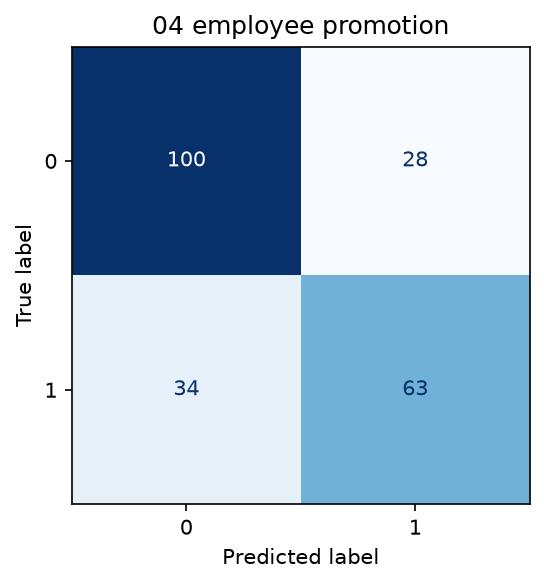

In [3]:
n = 900
X = pd.DataFrame({'experience': rng.integers(0, 26, n),
    'performance_rating': rng.integers(1, 6, n),
    'training_score': rng.uniform(30, 100, n),
    'previous_achievements': rng.integers(0, 5, n)})
score = (0.7*(X.performance_rating-3) + 0.06*(X.training_score-65)
         + 0.35*X.previous_achievements + 0.05*X.experience - 1.8)
y = rng.binomial(1, 1/(1 + np.exp(-score)))
print('Labels: 0 = not promoted; 1 = promoted')
model = DecisionTreeClassifier(max_depth=5, min_samples_leaf=15,
                               random_state=SEED)
metrics = evaluate(model, X, y, '04_employee_promotion')
print('Feature importances:')
print(pd.Series(model.feature_importances_, index=X.columns).round(3))

### Result and conclusion
Measured results: accuracy = 0.7244; macro_f1 = 0.7168; baseline_accuracy = 0.5689. Simulated labels encode a teaching rule; feature importance is not evidence that a factor causes promotion.